# 02 — Exploratory Data Analysis

Stage 03. Looks at the PM2.5 distribution, time-series patterns, missingness, outliers, daily and seasonal cycles, autocorrelation and weather relationships. **Descriptive only:** no splits, features or models. Figures are saved to `results/figures/`.

*Caveat:* this EDA covers the full 2010–2014 period because the test period is only defined in Stage 04. Findings are used only for qualitative design choices (which lags to use, the seasonal period), never for tuning.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.stattools import acf, pacf

from src.data import load_raw, validate, missing_runs
from src import plot_style as ps

ps.apply()
df = load_raw(); validate(df)
pm = df['pm25']
SEASON = {12: 'Winter (DJF)', 1: 'Winter (DJF)', 2: 'Winter (DJF)', 3: 'Spring (MAM)', 4: 'Spring (MAM)', 5: 'Spring (MAM)',
          6: 'Summer (JJA)', 7: 'Summer (JJA)', 8: 'Summer (JJA)', 9: 'Autumn (SON)', 10: 'Autumn (SON)', 11: 'Autumn (SON)'}
SEASONS = ['Winter (DJF)', 'Spring (MAM)', 'Summer (JJA)', 'Autumn (SON)']
season = pd.Series(df.index.month.map(SEASON), index=df.index)

## 1. Distribution of PM2.5

In [2]:
pd.Series({'skewness': pm.skew(), 'skewness of log1p': np.log1p(pm).skew(),
           **{f'q{int(q*100)}': pm.quantile(q) for q in [.1, .25, .5, .75, .9, .99]},
           'mean': pm.mean(), 'max': pm.max()}).round(2).to_frame('PM2.5 (µg/m³)').T

,skewness,skewness of log1p,q10,q25,q50,q75,q90,q99,mean,max
PM2.5 (µg/m³),1.8,-0.3,14.0,29.0,72.0,137.0,221.0,420.0,98.61,994.0


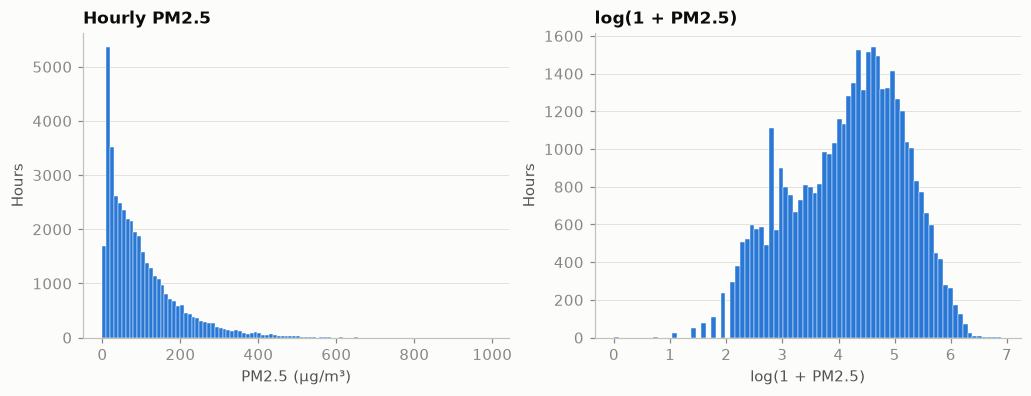

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(pm.dropna(), bins=100, color=ps.PRIMARY, edgecolor=ps.SURFACE, linewidth=0.3)
axes[0].set(title='Hourly PM2.5', xlabel='PM2.5 (µg/m³)', ylabel='Hours')
axes[1].hist(np.log1p(pm.dropna()), bins=80, color=ps.PRIMARY, edgecolor=ps.SURFACE, linewidth=0.3)
axes[1].set(title='log(1 + PM2.5)', xlabel='log(1 + PM2.5)', ylabel='Hours')
for ax in axes: ax.grid(axis='x', visible=False)
ps.save(fig, 'eda_01_distribution'); plt.show()

## 2. Time series, trend and missingness over time

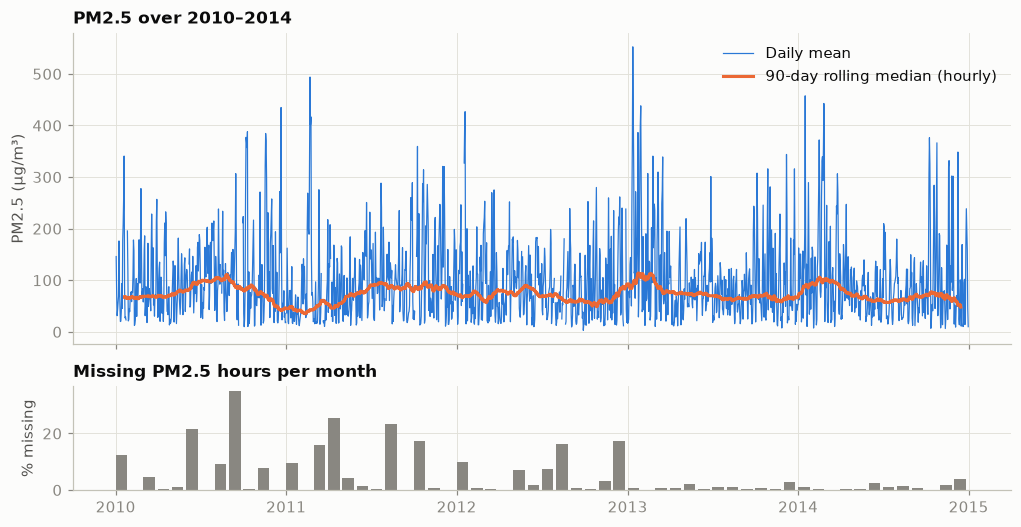

In [4]:
daily = pm.resample('D').mean()
trend = pm.rolling(24 * 90, center=True, min_periods=24 * 60).median()
miss_m = pm.isna().resample('MS').mean() * 100

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5.4), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
a1.plot(daily.index, daily, color=ps.PRIMARY, linewidth=0.8, label='Daily mean')
a1.plot(trend.index, trend, color=ps.SERIES[1], linewidth=2, label='90-day rolling median (hourly)')
a1.set(title='PM2.5 over 2010–2014', ylabel='PM2.5 (µg/m³)'); a1.legend(loc='upper right')
a2.bar(miss_m.index, miss_m, width=25, color=ps.MUTED, align='edge')
a2.set(title='Missing PM2.5 hours per month', ylabel='% missing')
a2.xaxis.set_major_locator(mdates.YearLocator()); a2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ps.save(fig, 'eda_02_timeseries_missingness'); plt.show()

In [5]:
by_year = pm.groupby(df.index.year)
pd.DataFrame({'mean': by_year.mean(), 'median': by_year.median(), 'p90': by_year.quantile(.9),
              '% missing': pm.isna().groupby(df.index.year).mean() * 100}).round(1).T

timestamp,2010,2011,2012,2013,2014
mean,104.0,99.1,90.5,101.7,97.7
median,79.0,71.0,69.0,71.5,72.0
p90,225.0,232.0,197.0,231.0,221.0
% missing,7.6,8.3,5.6,0.9,1.1


### Is missingness related to pollution level or time of day?

In [6]:
runs = missing_runs(pm)
before = pm.reindex(runs['start'] - pd.Timedelta(hours=1))
after = pm.reindex(runs['end'] + pd.Timedelta(hours=1))
pd.Series({'median PM2.5, all observed hours': pm.median(),
           'median PM2.5 in the hour before a gap': before.median(),
           'median PM2.5 in the hour after a gap': after.median()}).round(1).to_frame('µg/m³')

,µg/m³
"median PM2.5, all observed hours",72.0
median PM2.5 in the hour before a gap,67.0
median PM2.5 in the hour after a gap,74.5


In [7]:
pm.isna().groupby(df.index.hour).mean().mul(100).round(1).to_frame('% missing by hour').T

timestamp,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
% missing by hour,5.0,4.4,4.8,4.4,4.5,4.7,4.7,4.8,4.8,4.8,...,4.9,4.8,4.9,4.6,4.1,4.6,4.7,4.7,4.7,4.6


## 3. Outliers and extreme episodes

In [8]:
thr = pd.Series({t: int(pm.gt(t).sum()) for t in [250, 300, 500]}, name='hours above')
thr.index = [f'> {t} µg/m³' for t in thr.index]
thr.to_frame().T

,> 250 µg/m³,> 300 µg/m³,> 500 µg/m³
hours above,3053,1759,125


In [9]:
pm.gt(300).groupby(season).mean().mul(100).reindex(SEASONS).round(2).to_frame('% of hours > 300 µg/m³').T

timestamp,Winter (DJF),Spring (MAM),Summer (JJA),Autumn (SON)
% of hours > 300 µg/m³,8.64,1.52,0.61,5.39


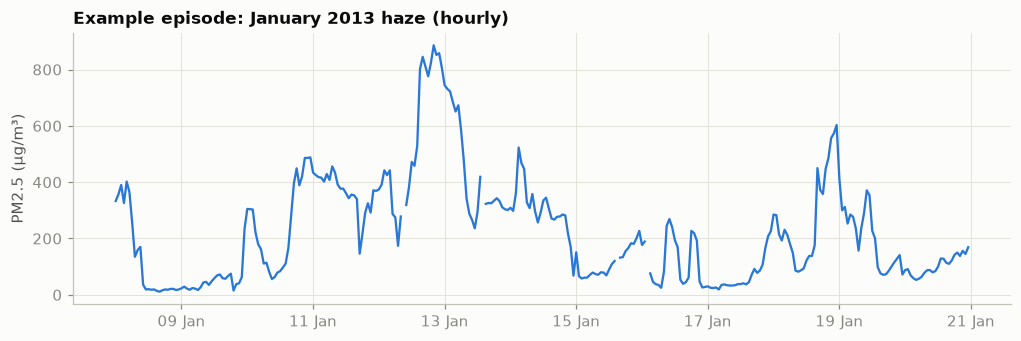

In [10]:
ep = pm['2013-01-08':'2013-01-20']
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(ep.index, ep, color=ps.PRIMARY, linewidth=1.5)
ax.set(title='Example episode: January 2013 haze (hourly)', ylabel='PM2.5 (µg/m³)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ps.save(fig, 'eda_03_episode_jan2013'); plt.show()

Within this example, PM2.5 rises over hours to days and can fall by several hundred µg/m³ within a few hours. *Hypothesis (not tested here):* these sharp drops coincide with wind shifts (see section 6), so forecast errors may be largest when an episode ends. Stage 08 error analysis can test this.

In [11]:
d1 = pm.diff()
pd.Series({'median |Δ| (1 h)': d1.abs().median(), 'mean |Δ| (1 h)': d1.abs().mean(),
           'p99 |Δ| (1 h)': d1.abs().quantile(.99), 'max |Δ| (1 h)': d1.abs().max(),
           '% of hours with |Δ| > 100': (d1.abs() > 100).mean() * 100}).round(2).to_frame('µg/m³').T

,median |Δ| (1 h),mean |Δ| (1 h),p99 |Δ| (1 h),max |Δ| (1 h),% of hours with |Δ| > 100
µg/m³,7.0,12.87,91.58,769.0,0.77


*These are descriptive hour-to-hour changes over all data, not a baseline evaluation. Baselines are evaluated under the Stage 04 protocol.*

## 4. Daily, weekly and seasonal patterns

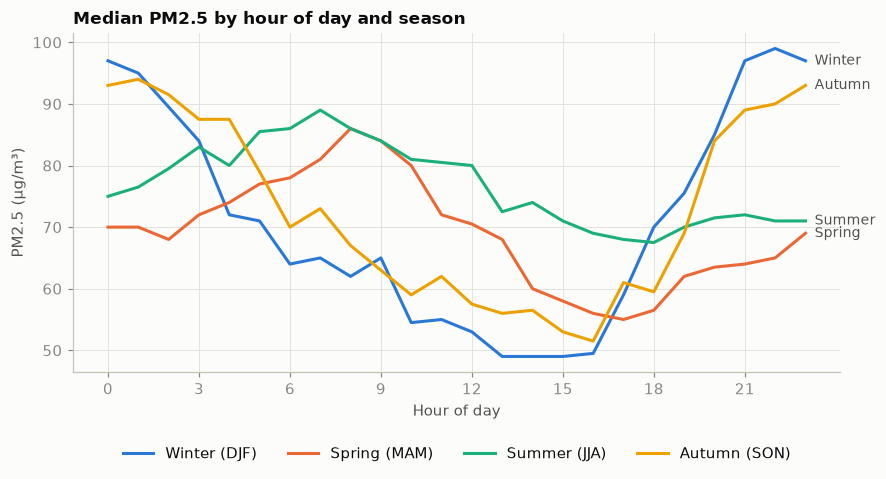

In [12]:
prof = pm.groupby([season, df.index.hour]).median().unstack(0)[SEASONS]
fig, ax = plt.subplots(figsize=(9, 4))
for i, s in enumerate(SEASONS):
    ax.plot(prof.index, prof[s], color=ps.SERIES[i], label=s)
    ax.annotate(s.split()[0], (23, prof[s].iloc[-1]), xytext=(6, 0), textcoords='offset points',
                va='center', fontsize=9, color=ps.INK_2)
ax.set(title='Median PM2.5 by hour of day and season', xlabel='Hour of day', ylabel='PM2.5 (µg/m³)', xticks=range(0, 24, 3))
ax.legend(loc='upper center', ncol=4, bbox_to_anchor=(0.5, -0.18))
ps.save(fig, 'eda_04_hourly_profile'); plt.show()

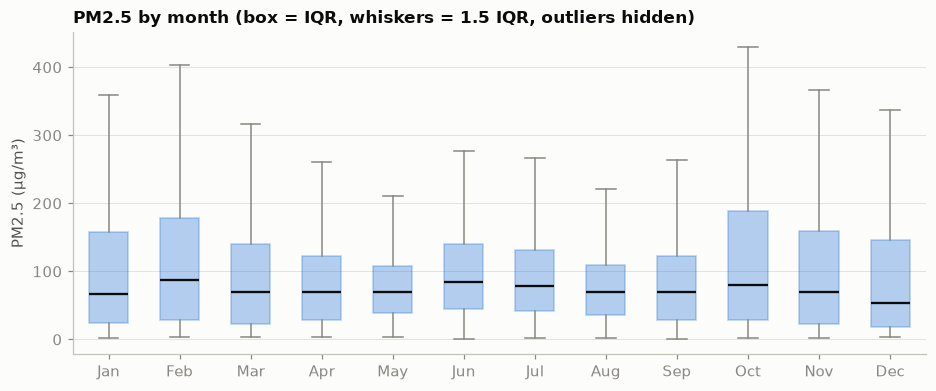

In [13]:
fig, ax = plt.subplots(figsize=(10, 3.8))
data = [pm[df.index.month == m].dropna() for m in range(1, 13)]
ax.boxplot(data, tick_labels=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'],
           widths=0.55, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor=ps.SERIES[0], edgecolor=ps.SERIES[0], alpha=0.35),
           medianprops=dict(color=ps.INK, linewidth=1.5), whiskerprops=dict(color=ps.MUTED), capprops=dict(color=ps.MUTED))
ax.set(title='PM2.5 by month (box = IQR, whiskers = 1.5 IQR, outliers hidden)', ylabel='PM2.5 (µg/m³)')
ax.grid(axis='x', visible=False)
ps.save(fig, 'eda_05_monthly_box'); plt.show()

In [14]:
g = pm.groupby(season)
pd.DataFrame({'median': g.median(), 'mean': g.mean(), 'p90': g.quantile(.9), 'std': g.std()}).reindex(SEASONS).round(1).T

timestamp,Winter (DJF),Spring (MAM),Summer (JJA),Autumn (SON)
median,70.0,69.0,77.0,73.0
mean,112.8,87.2,90.4,104.2
p90,288.0,186.0,181.0,252.0
std,119.2,73.4,64.2,99.0


In [15]:
pm.groupby(df.index.dayofweek).median().rename(dict(enumerate(['Mon','Tue','Wed','Thu','Fri','Sat','Sun']))).to_frame('median PM2.5').T

timestamp,Mon,Tue,Wed,Thu,Fri,Sat,Sun
median PM2.5,70.0,72.0,67.0,71.0,77.0,79.0,71.0


## 5. Autocorrelation
ACF uses `missing='conservative'` (pairs involving NaN are skipped). PACF needs a gap-free series, so it is computed on the observed series with gaps of ≤ 3 h linearly interpolated and longer gaps dropped. This is for diagnostics only, not a preprocessing decision.

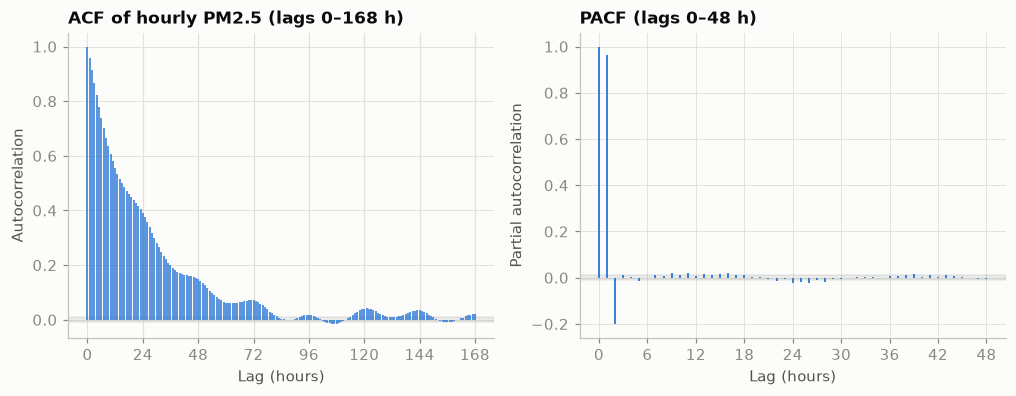

In [16]:
LAGS = 24 * 7
r = acf(pm, nlags=LAGS, missing='conservative')
p = pacf(pm.interpolate(limit=3, limit_area='inside').dropna(), nlags=48)
ci = 1.96 / np.sqrt(pm.notna().sum())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.vlines(range(LAGS + 1), 0, r, color=ps.PRIMARY, linewidth=1)
for k in [24, 48, 72, 96, 120, 144, 168]: a1.axvline(k, color=ps.GRID, linewidth=0.8, zorder=0)
a1.axhspan(-ci, ci, color=ps.MUTED, alpha=0.15)
a1.set(title='ACF of hourly PM2.5 (lags 0–168 h)', xlabel='Lag (hours)', ylabel='Autocorrelation', xticks=range(0, LAGS + 1, 24))
a2.vlines(range(49), 0, p, color=ps.PRIMARY, linewidth=1.2)
a2.axhspan(-ci, ci, color=ps.MUTED, alpha=0.15)
a2.set(title='PACF (lags 0–48 h)', xlabel='Lag (hours)', ylabel='Partial autocorrelation', xticks=range(0, 49, 6))
ps.save(fig, 'eda_06_acf_pacf'); plt.show()

In [17]:
pd.DataFrame({'ACF': r[[1, 2, 3, 6, 12, 24, 48, 72, 168]]}, index=[1, 2, 3, 6, 12, 24, 48, 72, 168]).round(3).T

,1,2,3,6,12,24,48,72,168
ACF,0.959,0.914,0.868,0.739,0.556,0.39,0.149,0.071,0.022


In [18]:
pd.DataFrame({'PACF': p[[1, 2, 3, 4, 6, 24, 25]]}, index=[1, 2, 3, 4, 6, 24, 25]).round(3).T

,1,2,3,4,6,24,25
PACF,0.965,-0.199,0.013,0.004,0.0,-0.021,-0.019


## 6. Relationships with weather variables
These are **same-hour** associations (Spearman, robust to skew and outliers). They describe co-variation and are not causal. Whether a variable can be used as a feature depends on what is known at prediction time (Stage 04).

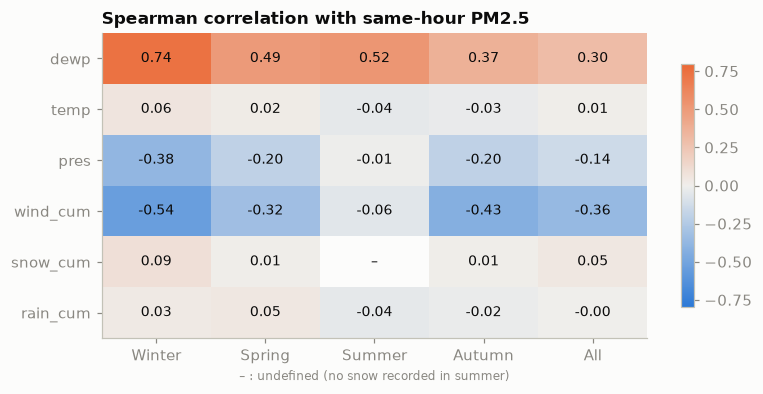

,Winter (DJF),Spring (MAM),Summer (JJA),Autumn (SON),All
dewp,0.74,0.49,0.52,0.37,0.30
temp,0.06,0.02,-0.04,-0.03,0.01
pres,-0.38,-0.20,-0.01,-0.20,-0.14
wind_cum,-0.54,-0.32,-0.06,-0.43,-0.36
snow_cum,0.09,0.01,NaN,0.01,0.05
rain_cum,0.03,0.05,-0.04,-0.02,-0.00


In [19]:
cols = ['dewp', 'temp', 'pres', 'wind_cum', 'snow_cum', 'rain_cum']
corr = pd.DataFrame({s: df[season == s][['pm25'] + cols].corr('spearman')['pm25'][cols] for s in SEASONS})
corr['All'] = df[['pm25'] + cols].corr('spearman')['pm25'][cols]
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('div', ps.DIVERGING)
fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(corr.values, cmap=cmap, vmin=-0.8, vmax=0.8, aspect='auto')
ax.set_xticks(range(corr.shape[1]), [c.split()[0] for c in corr.columns]); ax.set_yticks(range(len(cols)), cols)
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        v = corr.iat[i, j]
        ax.text(j, i, '–' if np.isnan(v) else f'{v:.2f}', ha='center', va='center', fontsize=9, color=ps.INK)
ax.set_xlabel('– : undefined (no snow recorded in summer)', fontsize=8, color=ps.MUTED)
ax.grid(False); ax.set_title('Spearman correlation with same-hour PM2.5')
fig.colorbar(im, ax=ax, shrink=0.8)
ps.save(fig, 'eda_07_weather_corr'); plt.show()
corr.round(2)

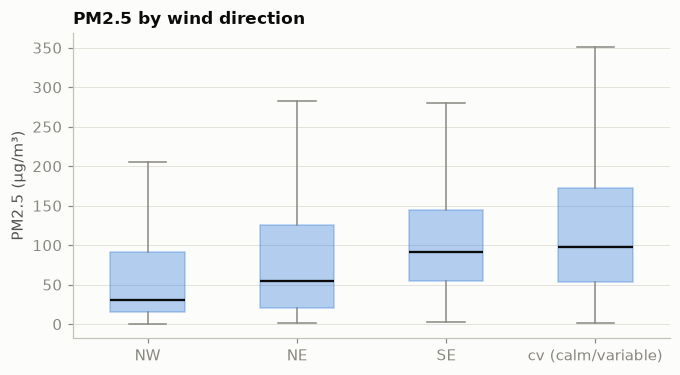

wind_dir,NE,NW,SE,cv
median,55.0,31.0,91.0,98.0
mean,90.2,70.1,110.8,126.2
count,4756.0,13484.0,14573.0,8944.0


In [20]:
order = ['NW', 'NE', 'SE', 'cv']
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.boxplot([pm[df['wind_dir'] == w].dropna() for w in order], tick_labels=['NW', 'NE', 'SE', 'cv (calm/variable)'],
           widths=0.5, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor=ps.SERIES[0], edgecolor=ps.SERIES[0], alpha=0.35),
           medianprops=dict(color=ps.INK, linewidth=1.5), whiskerprops=dict(color=ps.MUTED), capprops=dict(color=ps.MUTED))
ax.set(title='PM2.5 by wind direction', ylabel='PM2.5 (µg/m³)'); ax.grid(axis='x', visible=False)
ps.save(fig, 'eda_08_wind_dir'); plt.show()
pm.groupby(df['wind_dir'], observed=True).agg(['median', 'mean', 'count']).round(1).T

In [21]:
bins = pd.cut(df['wind_cum'], [0, 2, 5, 10, 25, 50, 100, 600])
pm.groupby(bins, observed=True).agg(['median', 'count']).round(1).T

wind_cum,"(0, 2]","(2, 5]","(5, 10]","(10, 25]","(25, 50]","(50, 100]","(100, 600]"
median,101.0,80.0,76.0,63.0,59.0,29.0,15.0
count,13072.0,7575.0,4859.0,6694.0,4457.0,2643.0,2457.0


### Which current values relate to PM2.5 one hour later?
Correlation of variables at time *t* with PM2.5 at *t+1* (the proposed forecast target).

In [22]:
nxt = pm.shift(-1)
pd.Series({c: df[c].corr(nxt, method='spearman') for c in ['pm25'] + cols}).round(3).to_frame('Spearman with PM2.5(t+1)').T

,pm25,dewp,temp,pres,wind_cum,snow_cum,rain_cum
Spearman with PM2.5(t+1),0.965,0.296,0.009,-0.139,-0.373,0.047,-0.019


## 7. Findings (evidence-based)
1. **Strongly right-skewed:** median 72, mean 98.6, p99 420, max 994 µg/m³ (skew 1.8). The log scale is nearly symmetric (skew −0.3), so RMSE will be dominated by high-pollution hours. The comb pattern at low values on the log scale comes from integer-valued measurements.
2. **No clear long-term trend:** annual medians are 69–79 µg/m³. Missingness is much higher in 2010–2012 than in 2013–2014.
3. **Missing data is not obviously linked to pollution level:** PM2.5 around gaps is similar to the overall median (see table).
4. **Episodes, not isolated spikes:** high values build up over days and clear quickly; 1-hour changes are usually small (median 7 µg/m³) but have a heavy tail (max 769).
5. **Daily cycle differs by season:** every season has its minimum in the afternoon or early evening (13:00–18:00 depending on season). In winter and autumn, PM2.5 is highest in the late evening and overnight (winter median ≈ 99 at 22:00 vs ≈ 49 at 13:00–15:00). In spring and summer, it peaks in the morning (≈ 86–89 around 07:00–08:00). Hour of day should therefore be combined with season.
6. **Seasonality is mainly in the tail:** seasonal medians are similar (69–77), but winter has the highest mean, p90 and spread, and the most hours above 300 µg/m³. The weekly pattern is weak.
7. **Very high short-lag dependence:** ACF is 0.96 at lag 1 and decays to 0.39 at 24 h and about 0.02 at 168 h. PACF is 0.97 at lag 1, about −0.2 at lag 2 and near zero afterwards. This supports a persistence baseline and a small set of short lags, with a 24 h lag mainly for the daily cycle.
8. **Weather:** wind is the strongest weather signal. NW wind (median 31) and long-lasting wind (high `wind_cum`) go with clean air; calm/variable and SE wind go with high PM2.5. Dew point (humidity) is positively associated, strongest in winter (ρ = 0.74). Same-hour temperature and precipitation show little association.

**Limitations:** associations are descriptive and same-hour; EDA used the full period (see caveat at the top); PACF used short-gap interpolation for diagnostics only.